In [1]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [2]:
# Constants
RANDOMSTATE = 1082
TRAIN_SIZE = 0.2

In [3]:
# Load the dataset
try:
    df = pd.read_csv("../../../Datasets/csv/UAVATTACK/spoofing-merged-gps-only.csv")
except FileNotFoundError:
    print("Error: The file '../../../Datasets/csv/UAVATTACK/spoofing-merged-gps-only.csv' was not found.")
    exit()

In [4]:
# Data Preprocessing

# Clean up column names
df.columns = df.columns.str.replace('[\\[\\]<>]', '_', regex=True)

# Drop label
drop_cols = ['timestamp', 'label']
X = df.drop(columns=drop_cols)
y = df['label']

if y.dtype == object or y.dtype.name == 'category':
    from sklearn.preprocessing import LabelEncoder
    le = LabelEncoder()
    y = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=TRAIN_SIZE, random_state=RANDOMSTATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=0.2,
    random_state=RANDOMSTATE,
    stratify=y
)

In [6]:
# Build and train XGBoost classifier
model = xgb.XGBClassifier(
    objective='binary:logistic',
    random_state=RANDOMSTATE,
    eval_metric='mae',
)
model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mae', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [7]:
# Predict and evaluate
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy on Test Set: {accuracy * 100:.2f}%")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy on Test Set: 99.79%
Confusion Matrix:
[[2500    0]
 [   6  392]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2500
           1       1.00      0.98      0.99       398

    accuracy                           1.00      2898
   macro avg       1.00      0.99      1.00      2898
weighted avg       1.00      1.00      1.00      2898



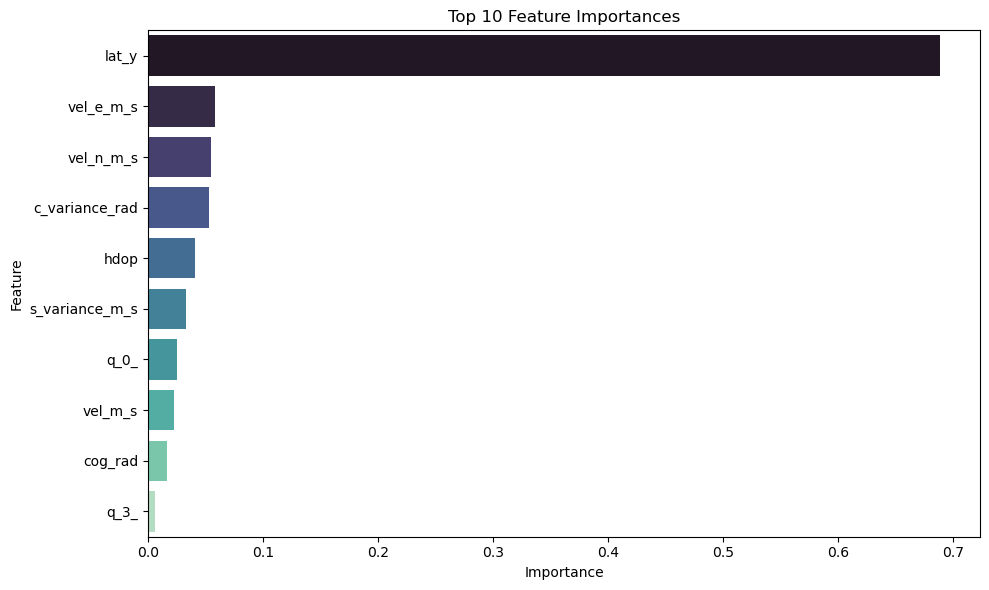

In [8]:
importances = model.feature_importances_

# Create a DataFrame for feature importances
feat_imp_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
})

# Sort by importance descending
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feat_imp_df.head(10),
    x='Importance',
    y='Feature',
    palette='mako',
    hue='Feature',
    legend=False
)
plt.title('Top 10 Feature Importances')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=800)
plt.show()

Possibly calculated variance in rad or current, Horizontal dilution of precision, and course over ground are the most important features.